# Kidney / CKD Risk Prediction Module
### A component of the *Multimodal, Explainable and Longitudinal Diabetes Complication Screening & Risk Monitoring System*

**Research question:** Can machine-learning-based CKD risk stratification, built from routinely
available clinical, urinalysis and comorbidity data, provide a **useful, well-calibrated, and
interpretable screening signal** — rather than a black-box diagnosis?

**Scope of this notebook.** The uploaded file `kidney_disease.csv` is the classic UCI
*Chronic Kidney Disease* dataset (400 patients, cross-sectional, single hospital, single
snapshot per patient). It is **not** a diabetes-specific dataset, it contains **no dates,
no repeated visits and no patient trajectories**. Therefore:

- This module is described honestly as **CKD Risk Prediction / Screening**, *not* "diabetic
  kidney disease" — the dataset does not support that narrower claim (it does record `dm`,
  diabetes mellitus comorbidity status, as one input feature, which is useful but not sufficient
  to justify a diabetic-nephropathy-specific label).
- No genuine longitudinal model can be trained here (see Section 26). We instead specify the
  longitudinal architecture that *would* be used once repeated-visit data is available.
- All outputs are **research/screening signals**, not diagnoses (Section 36).

This notebook is written to run top-to-bottom in Google Colab or local Jupyter, once
`DATA_PATH` (below) points at the uploaded CSV.


In [1]:
# Environment setup — run once.
# In Colab, uncomment the pip install line (these packages are usually already present locally).
# !pip install -q scikit-learn xgboost shap imbalanced-learn

import sys, platform, random
import numpy as np
import pandas as pd

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

import sklearn
print("Python     :", sys.version.split()[0])
print("Platform   :", platform.platform())
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

try:
    import xgboost
    XGB_AVAILABLE = True
    print("XGBoost    :", xgboost.__version__)
except ImportError:
    XGB_AVAILABLE = False
    print("XGBoost not available -> will fall back to HistGradientBoostingClassifier")

try:
    import shap
    SHAP_AVAILABLE = True
    print("SHAP       :", shap.__version__)
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not available -> Section 20 will be skipped with a warning")

import warnings
warnings.filterwarnings("ignore")


Python     : 3.12.3
Platform   : Linux-6.18.44-fc-v24-x86_64-with-glibc2.39
NumPy      : 2.4.4
Pandas     : 3.0.2
scikit-learn: 1.8.0
XGBoost    : 3.4.1


SHAP       : 0.52.0


## 2. Project Architecture — Where This Module Fits

```
                        PATIENT
                           |
                     Health Profile
                 ______________|______________
                |                              |
          Questionnaire                  Clinical / Lab Data
                |                              |
          Diabetes Risk                  >>> KIDNEY / CKD MODEL <<<   (this notebook)
                                                |
                 ______________________________|_______________________
                |                    |                                 |
             Retina CNN          Foot (DFU) CNN                 (other complication
             (Grad-CAM)           (Grad-CAM)                     screens, future)
                |____________________|_________________________________|
                                     |
                              Risk Fusion Engine
                                     |
                          Complication Knowledge Graph
                                     |
                           Next-Best-Screening Logic
                                     |
                          Longitudinal Monitoring (future)
                                     |
                                    XAI
                                     |
                          Patient Screening Report
```

The kidney module is one **independent, modular** predictor. Its output (a calibrated CKD-risk
probability + SHAP-based reasons) is one input to the downstream Risk Fusion Engine — it is
**not** trained jointly with the retina/foot image models, and this notebook does **not**
concatenate this CSV with any other module's data (that would misrepresent unrelated patients
as if they were the same person).


## 3. Dataset Description

**Source file:** `kidney_disease.csv` (as uploaded). This matches the well-known **UCI Chronic
Kidney Disease** dataset (400 patients from a hospital in Tamil Nadu, India, collected over
~2 months). We treat it purely as data on disk and re-derive every fact about it below rather
than assuming prior knowledge — but we flag the match because it has a well-documented history
of stray whitespace/tab characters and near-perfect class separability, both of which we verify
independently in Sections 4–8.


In [2]:
DATA_PATH = "kidney_disease.csv"   # <-- update this path if needed (e.g. /content/kidney_disease.csv in Colab)

def load_data(path: str) -> pd.DataFrame:
    """Load the raw CKD CSV without any cleaning, preserving original strings."""
    df = pd.read_csv(path)
    return df

raw_df = load_data(DATA_PATH)
print("Raw shape:", raw_df.shape)
raw_df.head()


Raw shape: (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


## 4. Dataset Audit

We inspect the file mechanically — no assumptions about column meaning yet.


In [3]:
def audit_dataset(df: pd.DataFrame) -> dict:
    """Produce a structural audit of a raw dataframe."""
    audit = {}
    audit["shape"] = df.shape
    audit["columns"] = df.columns.tolist()
    audit["dtypes"] = df.dtypes.astype(str).to_dict()
    audit["missing_count"] = df.isna().sum().to_dict()
    audit["missing_pct"] = (df.isna().mean() * 100).round(2).to_dict()
    audit["n_duplicate_rows"] = int(df.duplicated().sum())
    audit["n_unique"] = df.nunique(dropna=True).to_dict()
    return audit

audit = audit_dataset(raw_df)
print("Shape (rows, cols):", audit["shape"])
print("Duplicate rows    :", audit["n_duplicate_rows"])

audit_table = pd.DataFrame({
    "dtype": audit["dtypes"],
    "missing_count": audit["missing_count"],
    "missing_pct": audit["missing_pct"],
    "n_unique": audit["n_unique"],
}).sort_values("missing_pct", ascending=False)
audit_table


Shape (rows, cols): (400, 26)
Duplicate rows    : 0


,dtype,missing_count,missing_pct,n_unique
rbc,str,152,38.00,2
rc,str,130,32.50,49
wc,str,105,26.25,92
pot,float64,88,22.00,40
sod,float64,87,21.75,34
pcv,str,70,17.50,44
pc,str,65,16.25,2
hemo,float64,52,13.00,115
su,float64,49,12.25,6
sg,float64,47,11.75,5


In [4]:
# Candidate target column inspection (Section 35: automatic dataset adaptation)
candidate_target_cols = [c for c in raw_df.columns if raw_df[c].nunique(dropna=True) <= 5 and c != "id"]
print("Low-cardinality candidate columns:", candidate_target_cols)
print()
print("classification value counts (raw, including stray whitespace/tabs):")
print(raw_df["classification"].value_counts(dropna=False))


Low-cardinality candidate columns: ['sg', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']

classification value counts (raw, including stray whitespace/tabs):
classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64


**Inference.** `classification` is the only column that is (a) clearly an outcome label in
plain English ("ckd" / "notckd"), (b) not a lab measurement, and (c) referenced nowhere else.
We therefore infer it as the target. A manual override variable is provided below in case this
inference is wrong for a different uploaded file.


In [5]:
TARGET_COLUMN = "classification"   # manual override point (Section 35)
ID_COLUMN = "id"                   # row index, not a clinical feature -> will be dropped

assert TARGET_COLUMN in raw_df.columns, f"{TARGET_COLUMN} not found in columns!"
print(f"Using TARGET_COLUMN = '{TARGET_COLUMN}'")


Using TARGET_COLUMN = 'classification'


## 5. Clinical Feature Mapping

Column abbreviations mapped to clinical meaning (standard UCI CKD documentation), together with
the modeling role we assign each one:

| Feature | Clinical meaning | Type | Modeling role |
|---|---|---|---|
| age | Age (years) | numeric | predictor |
| bp | Blood pressure (mm Hg, diastolic) | numeric | predictor |
| sg | Urine specific gravity | numeric (ordinal-like) | predictor |
| al | Albumin in urine (0-5 scale) | numeric (ordinal) | predictor |
| su | Sugar in urine (0-5 scale) | numeric (ordinal) | predictor |
| rbc | Red blood cells in urine (normal/abnormal) | categorical | predictor |
| pc | Pus cell in urine (normal/abnormal) | categorical | predictor |
| pcc | Pus cell clumps (present/notpresent) | categorical | predictor |
| ba | Bacteria in urine (present/notpresent) | categorical | predictor |
| bgr | Blood glucose random (mg/dL) | numeric | predictor |
| bu | Blood urea (mg/dL) | numeric | predictor (CKD-defining lab) |
| sc | Serum creatinine (mg/dL) | numeric | predictor (CKD-defining lab) |
| sod | Sodium (mEq/L) | numeric | predictor |
| pot | Potassium (mEq/L) | numeric | predictor |
| hemo | Hemoglobin (g/dL) | numeric | predictor |
| pcv | Packed cell volume (%) | numeric (stored as text) | predictor |
| wc | White blood cell count (cells/cumm) | numeric (stored as text) | predictor |
| rc | Red blood cell count (millions/cumm) | numeric (stored as text) | predictor |
| htn | Hypertension (yes/no) | categorical | predictor (comorbidity) |
| dm | Diabetes mellitus (yes/no) | categorical | predictor (comorbidity) |
| cad | Coronary artery disease (yes/no) | categorical | predictor (comorbidity) |
| appet | Appetite (good/poor) | categorical | predictor |
| pe | Pedal edema (yes/no) | categorical | predictor |
| ane | Anemia (yes/no) | categorical | predictor |
| classification | CKD / not CKD | categorical | **target** |

**Important scientific caveat (flagged now, revisited in Leakage Audit and Limitations):**
`bu` (blood urea) and `sc` (serum creatinine) are not just *correlated* with CKD — elevated
creatinine / reduced eGFR is literally part of the **clinical definition** used to diagnose CKD.
Including them is standard practice for a screening tool (that is what a clinician would look
at too), but it means we should **not** expect this to generalize as a "leading indicator" the
way a purely upstream predictor would — it is closer to "automating the recognition of already-
present clinical criteria" than to early risk forecasting. We discuss this honestly rather than
hide it.


## 6. Data Quality Audit

Several columns are stored as text due to stray whitespace/tab characters and a literal `"?"`
value in the source file (a documented quirk of this dataset). We quantify this before touching
anything.


In [6]:
def find_dirty_tokens(df: pd.DataFrame) -> pd.DataFrame:
    """Report non-standard tokens (stray whitespace, tabs, '?') per column."""
    report = []
    for c in df.columns:
        if df[c].dtype == object or str(df[c].dtype).startswith("str"):
            vals = df[c].astype(str)
            dirty_mask = vals.str.contains(r"\t|\?", regex=True, na=False) | (vals != vals.str.strip())
            n_dirty = int(dirty_mask.sum())
            if n_dirty > 0:
                examples = df.loc[dirty_mask, c].unique()[:5].tolist()
                report.append({"column": c, "n_dirty_values": n_dirty, "examples": examples})
    return pd.DataFrame(report)

dirty_report = find_dirty_tokens(raw_df)
dirty_report


,column,n_dirty_values,examples
0,rbc,152,[nan]
1,pc,65,[nan]
2,pcc,4,[nan]
3,ba,4,[nan]
4,pcv,72,"[nan, \t?, \t43]"
5,wc,108,"[nan, \t6200, \t8400, \t?]"
6,rc,131,"[nan, \t?]"
7,htn,2,[nan]
8,dm,8,"[ yes, \tno, \tyes, nan]"
9,cad,4,"[\tno, nan]"


Numeric-looking columns (`wc`, `rc`, `pcv`) are stored as text because of these stray tokens. We also check the *object* columns for inconsistent category spellings.

In [7]:
text_like_numeric_cols = ["wc", "rc", "pcv"]
for c in text_like_numeric_cols:
    print(c, "raw dtype:", raw_df[c].dtype, "| sample values:", raw_df[c].dropna().unique()[:6].tolist())

categorical_cols_raw = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane", "classification"]
for c in categorical_cols_raw:
    print(f"{c:15s}", raw_df[c].astype(str).str.strip().str.lower().unique())


wc raw dtype: str | sample values: ['7800', '6000', '7500', '6700', '7300', '6900']
rc raw dtype: str | sample values: ['5.2', '3.9', '4.6', '4.4', '5', '4.0']
pcv raw dtype: str | sample values: ['44', '38', '31', '32', '35', '39']
rbc             <StringArray>
[nan, 'normal', 'abnormal']
Length: 3, dtype: str
pc              <StringArray>
['normal', 'abnormal', nan]
Length: 3, dtype: str
pcc             <StringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
ba              <StringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
htn             <StringArray>
['yes', 'no', nan]
Length: 3, dtype: str
dm              <StringArray>
['yes', 'no', nan]
Length: 3, dtype: str
cad             <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
appet           <StringArray>
['good', 'poor', nan]
Length: 3, dtype: str
pe              <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
ane             <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
classificati

**Findings.** `dm` contains `' yes'`, `'\tno'`, `'\tyes'` variants of `yes`/`no`;
`cad` contains `'\tno'`; `classification` contains `'ckd\t'`. `wc`, `rc`, `pcv` contain a
literal `'\t?'` placeholder for missing values instead of a true NaN. None of these are
silently dropped — we standardize them explicitly in `clean_data()` and report exactly how many
records were affected.


In [8]:
def clean_data(df: pd.DataFrame, numeric_text_cols=None, categorical_cols=None) -> pd.DataFrame:
    """
    Standardize messy tokens without discarding any rows.
    Returns a cleaned copy + prints a change log.
    """
    numeric_text_cols = numeric_text_cols or ["wc", "rc", "pcv"]
    categorical_cols = categorical_cols or ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad",
                                             "appet", "pe", "ane", "classification"]
    out = df.copy()
    change_log = {}

    # 1) Strip whitespace/tabs from all object columns, convert literal '?' to NaN
    for c in out.columns:
        if out[c].dtype == object or str(out[c].dtype).startswith("str"):
            before = out[c].copy()
            out[c] = out[c].astype(str).str.strip().replace({"nan": np.nan, "?": np.nan, "": np.nan})
            n_changed = int((before.astype(str) != out[c].astype(str)).sum())
            if n_changed:
                change_log[c] = change_log.get(c, 0) + n_changed

    # 2) Coerce numeric-but-text columns to float
    for c in numeric_text_cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")

    # 3) Standardize categorical spelling/case
    for c in categorical_cols:
        out[c] = out[c].str.lower()

    # 4) Fix the known 'ckd\t' -> 'ckd' collapse (already handled by strip, verify)
    assert set(out["classification"].dropna().unique()) <= {"ckd", "notckd"}, out["classification"].unique()

    print("Columns with standardized text tokens (count of values touched):")
    for k, v in change_log.items():
        print(f"  {k:15s}: {v} values")
    return out

df_clean = clean_data(raw_df)
print()
print("classification after cleaning:", df_clean["classification"].value_counts().to_dict())
print("dm after cleaning            :", df_clean["dm"].value_counts(dropna=False).to_dict())
print("cad after cleaning           :", df_clean["cad"].value_counts(dropna=False).to_dict())


Columns with standardized text tokens (count of values touched):
  rbc            : 152 values
  pc             : 65 values
  pcc            : 4 values
  ba             : 4 values
  pcv            : 72 values
  wc             : 108 values
  rc             : 131 values
  htn            : 2 values
  dm             : 8 values
  cad            : 4 values
  appet          : 1 values
  pe             : 1 values
  ane            : 1 values
  classification : 2 values

classification after cleaning: {'ckd': 250, 'notckd': 150}
dm after cleaning            : {'no': 261, 'yes': 137, nan: 2}
cad after cleaning           : {'no': 364, 'yes': 34, nan: 2}


## 7. Clinical Sanity Check — Statistical Outlier vs Clinically Impossible Value

- A **statistical outlier** is a value that is far from the rest of the sample but still
  physiologically possible (e.g. a very sick patient with creatinine = 15 mg/dL).
- A **clinically impossible value** is one that could not occur in a living outpatient given
  standard reference ranges (e.g. serum sodium of 4.5 mEq/L is incompatible with life; normal
  range is ~135-145 mEq/L). These are far more likely to be **data entry errors** (e.g. a
  misplaced decimal point) than genuine measurements.

We do not delete either type automatically. Impossible values are treated as **missing** (set
to NaN) because treating a data-entry artifact as a true extreme value would corrupt the model;
genuine statistical outliers are left in the data and handled by using tree-based models (robust
to scale) and reporting robustness checks later (Section 24).


In [9]:
reference_ranges = {
    # column: (plausible_min, plausible_max) -- generous outpatient ranges, not tight clinical norms
    "age": (0, 110),
    "bp": (40, 200),      # diastolic BP mmHg
    "bgr": (20, 700),     # random glucose mg/dL
    "bu": (1, 300),       # blood urea mg/dL
    "sc": (0.1, 40),      # serum creatinine mg/dL (>40 essentially never survivable outpatient)
    "sod": (100, 180),    # sodium mEq/L
    "pot": (1.5, 9.0),    # potassium mEq/L (>9 typically fatal)
    "hemo": (2, 20),      # hemoglobin g/dL
    "pcv": (5, 60),       # packed cell volume %
}

def clinical_sanity_check(df, ranges):
    rows = []
    for col, (lo, hi) in ranges.items():
        impossible = df[(df[col] < lo) | (df[col] > hi)][col]
        rows.append({"feature": col, "plausible_range": f"[{lo}, {hi}]",
                     "n_clinically_impossible": int(impossible.notna().sum()),
                     "impossible_values": impossible.dropna().unique().tolist()[:5]})
    return pd.DataFrame(rows)

sanity_table = clinical_sanity_check(df_clean, reference_ranges)
sanity_table


,feature,plausible_range,n_clinically_impossible,impossible_values
0,age,"[0, 110]",0,[]
1,bp,"[40, 200]",0,[]
2,bgr,"[20, 700]",0,[]
3,bu,"[1, 300]",3,"[391.0, 322.0, 309.0]"
4,sc,"[0.1, 40]",2,"[76.0, 48.1]"
5,sod,"[100, 180]",1,[4.5]
6,pot,"[1.5, 9.0]",2,"[39.0, 47.0]"
7,hemo,"[2, 20]",0,[]
8,pcv,"[5, 60]",0,[]


In [10]:
def fix_impossible_values(df, ranges):
    """Set clinically impossible values to NaN (to be imputed later, inside the pipeline)."""
    out = df.copy()
    n_fixed_total = 0
    for col, (lo, hi) in ranges.items():
        mask = (out[col] < lo) | (out[col] > hi)
        n_fixed_total += int(mask.sum())
        out.loc[mask, col] = np.nan
    print(f"Total clinically-impossible values converted to NaN: {n_fixed_total}")
    return out

df_clean = fix_impossible_values(df_clean, reference_ranges)


Total clinically-impossible values converted to NaN: 8


## 8. Exploratory Data Analysis

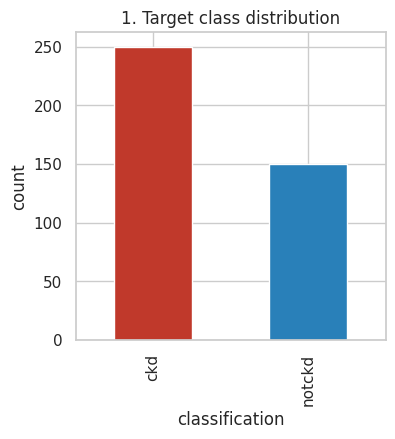

classification
ckd       0.625
notckd    0.375
Name: proportion, dtype: float64


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df_clean["target"] = (df_clean["classification"] == "ckd").astype(int)

fig, ax = plt.subplots(figsize=(4,4))
df_clean["classification"].value_counts().plot(kind="bar", ax=ax, color=["#c0392b","#2980b9"])
ax.set_title("1. Target class distribution")
ax.set_ylabel("count")
plt.show()
print(df_clean["classification"].value_counts(normalize=True).round(3))


**Interpretation.** The dataset is moderately imbalanced (roughly 62% CKD / 38% not-CKD), not severe, but still worth addressing explicitly (Section 15) rather than assuming balance.

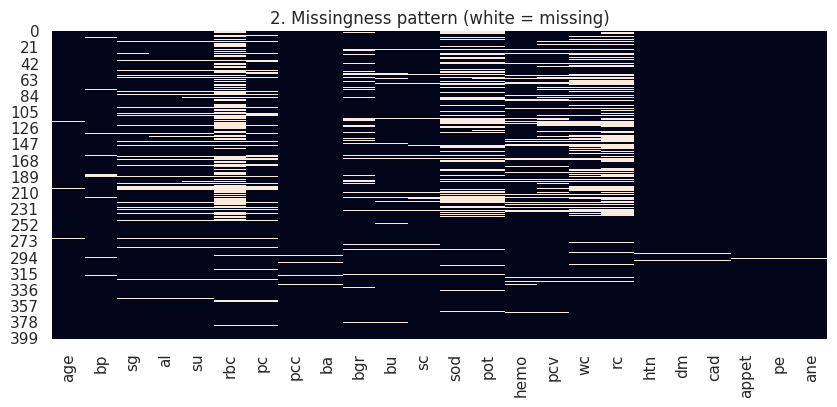

In [12]:
plt.figure(figsize=(10,4))
sns.heatmap(df_clean.drop(columns=["id","classification","target"]).isna(), cbar=False)
plt.title("2. Missingness pattern (white = missing)")
plt.show()


**Interpretation.** Missingness is spread unevenly across lab columns (`sod`, `pot`, `rc`, `wc` worst). No column is missing for *all* rows, and there is no obvious column-level MCAR vs MNAR pattern we can prove without metadata — we proceed conservatively with imputation inside the modeling pipeline (never before the train/test split).

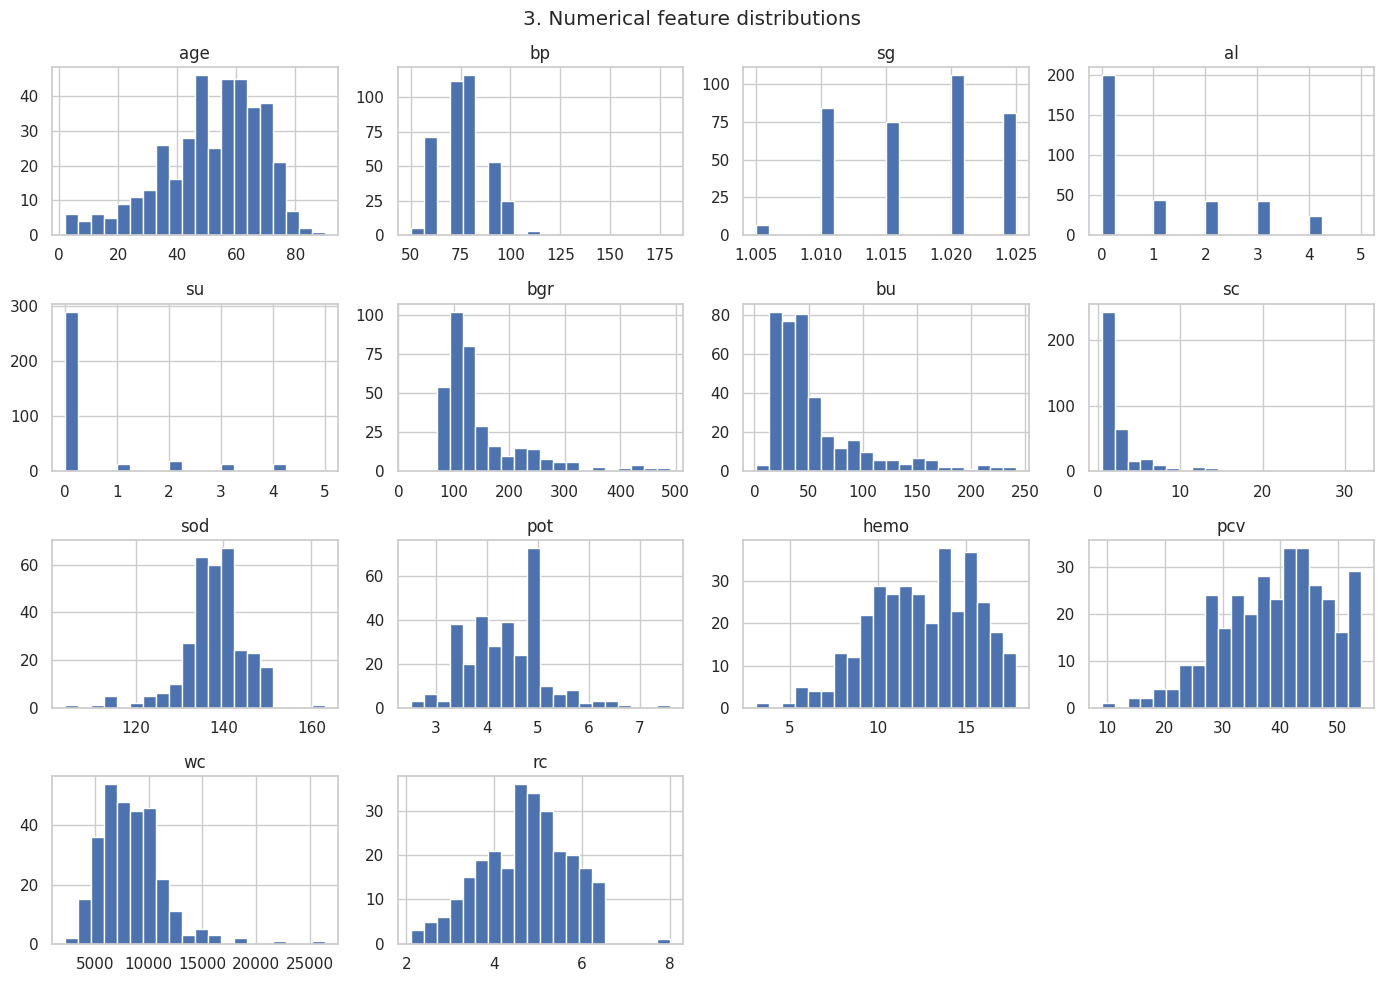

In [13]:
numeric_cols = ["age","bp","sg","al","su","bgr","bu","sc","sod","pot","hemo","pcv","wc","rc"]
categorical_cols = ["rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"]

df_clean[numeric_cols].hist(figsize=(14,10), bins=20)
plt.suptitle("3. Numerical feature distributions")
plt.tight_layout()
plt.show()


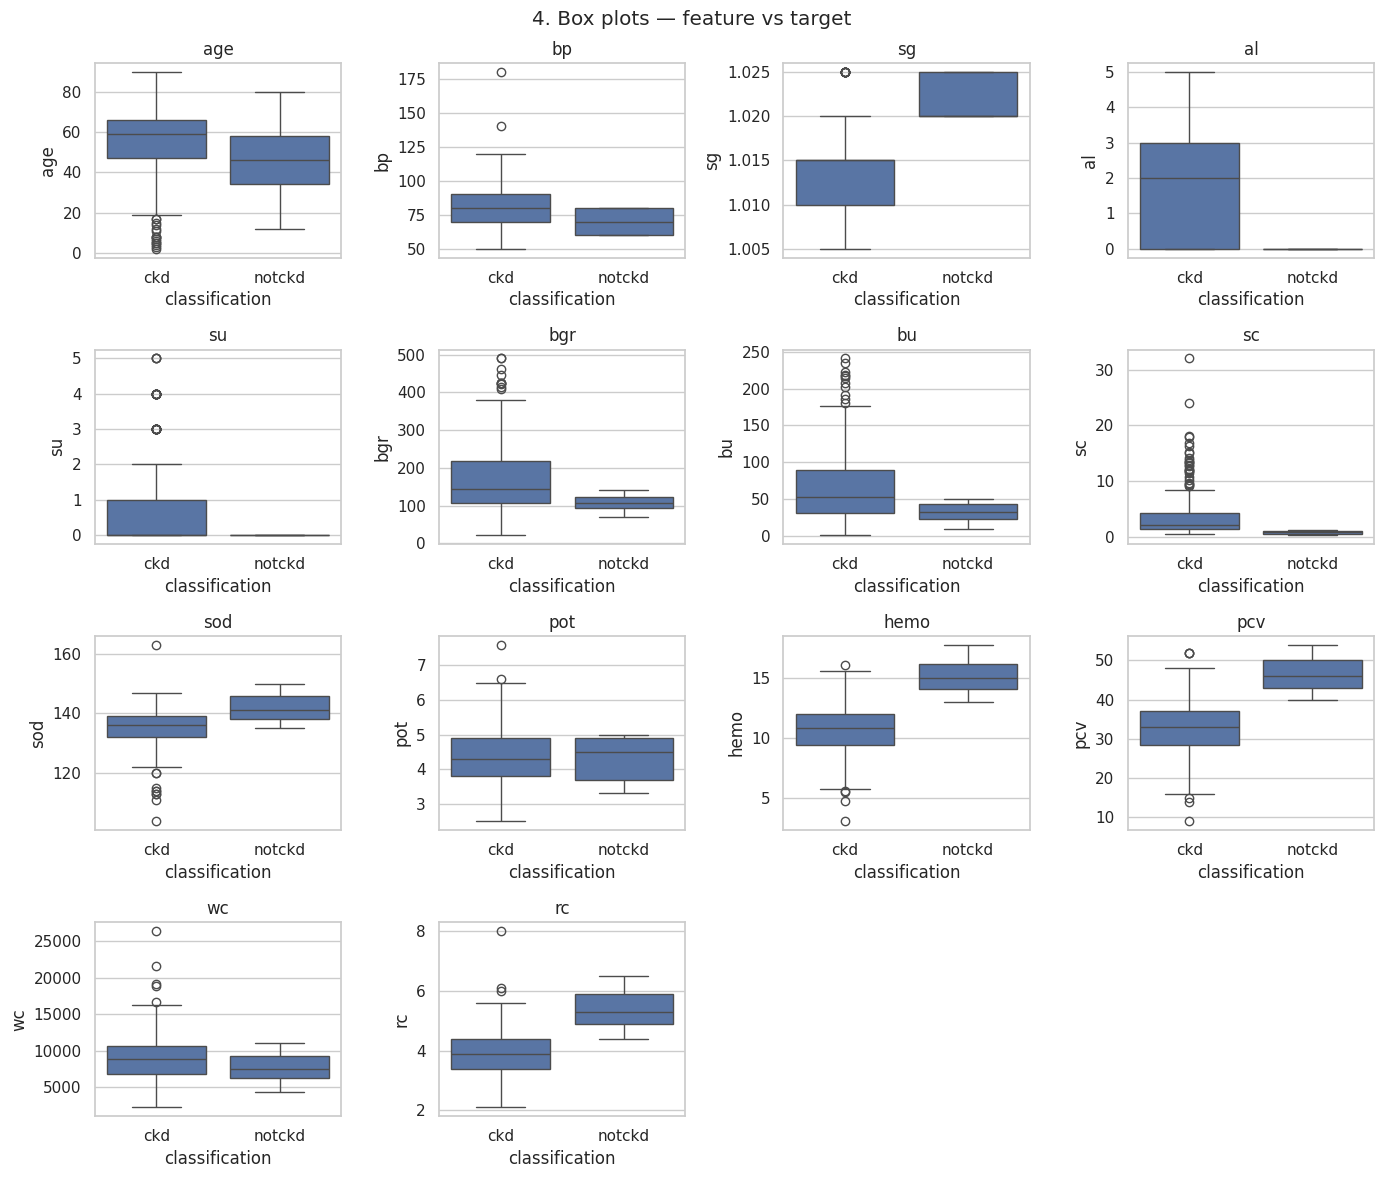

In [14]:
fig, axes = plt.subplots(4,4, figsize=(14,12))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(x=df_clean["classification"], y=df_clean[col], ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(numeric_cols):]:
    ax.axis("off")
plt.suptitle("4. Box plots — feature vs target")
plt.tight_layout()
plt.show()


**Interpretation.** `hemo`, `pcv`, `sc`, `bu`, `al` show the clearest separation between CKD and not-CKD — consistent with clinical expectation (anemia and reduced kidney clearance markers).

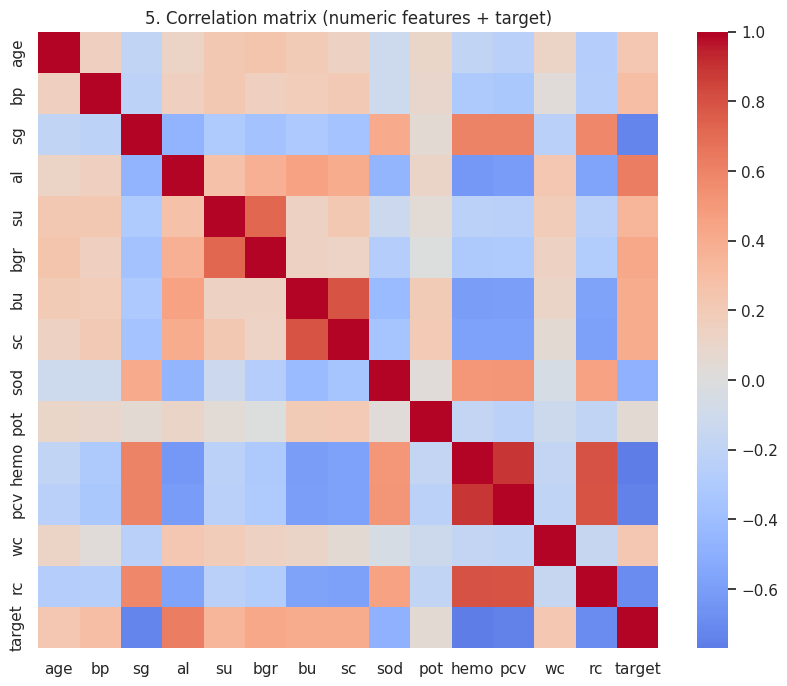

Top |correlation| with target:
hemo    0.768919
pcv     0.741427
sg      0.732163
rc      0.699089
al      0.627090
sod     0.490564
bgr     0.419672
sc      0.401504
Name: target, dtype: float64


In [15]:
plt.figure(figsize=(10,8))
corr = df_clean[numeric_cols + ["target"]].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", center=0)
plt.title("5. Correlation matrix (numeric features + target)")
plt.show()

print("Top |correlation| with target:")
print(corr["target"].drop("target").abs().sort_values(ascending=False).head(8))


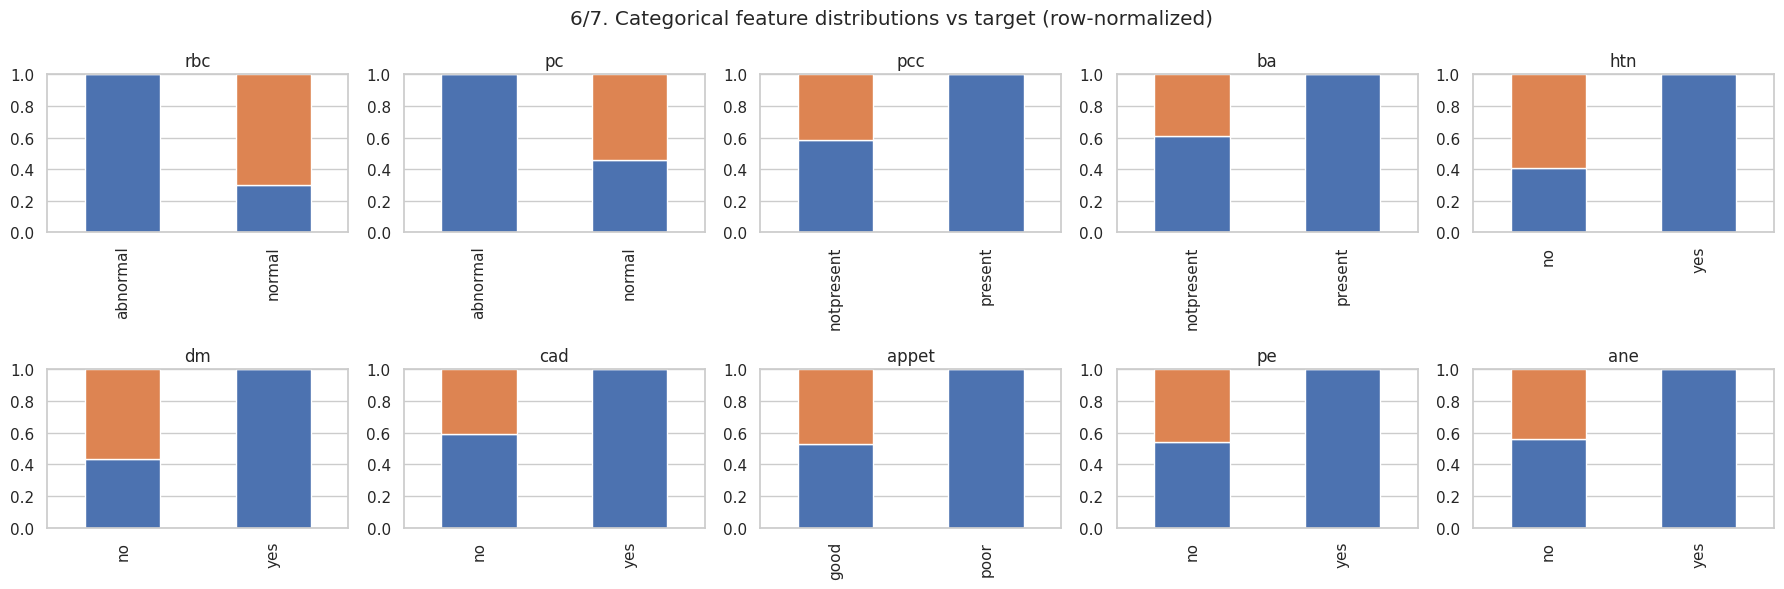

In [16]:
fig, axes = plt.subplots(2,5, figsize=(18,6))
for ax, col in zip(axes.flat, categorical_cols):
    pd.crosstab(df_clean[col], df_clean["classification"], normalize="index").plot(
        kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("6/7. Categorical feature distributions vs target (row-normalized)")
plt.tight_layout()
plt.show()


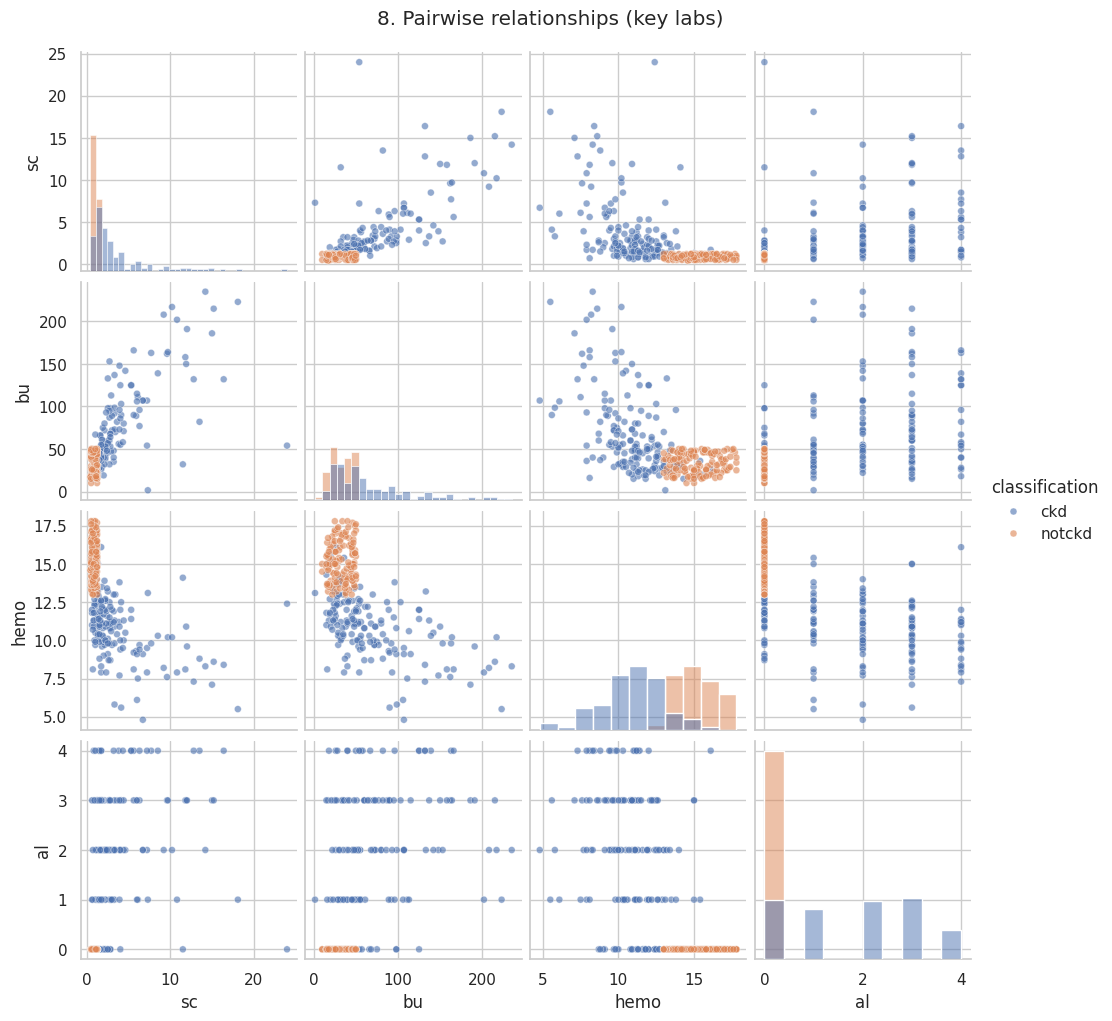

In [17]:
important_pairs = ["sc","bu","hemo","al"]
sns.pairplot(df_clean[important_pairs + ["classification"]].dropna(), hue="classification",
             diag_kind="hist", plot_kws={"alpha":0.6, "s":25})
plt.suptitle("8. Pairwise relationships (key labs)", y=1.02)
plt.show()


**Interpretation.** `sc` and `bu` are both elevated together in CKD patients (expected — both reflect reduced glomerular filtration), so they carry meaningfully overlapping information rather than fully independent signal.

## 9. Target Definition

The target is **binary**: `classification` in {`ckd`, `notckd`}. We map:

- `ckd` → **1**
- `notckd` → **0**

This is a diagnostic label already assigned in the source hospital record (not something we are
deriving), so the modeling task is **binary classification / screening-signal replication**,
not label creation.


In [18]:
print("Target mapping: ckd -> 1, notckd -> 0")
print(df_clean["target"].value_counts())
print("Class balance: {:.1f}% CKD vs {:.1f}% not-CKD".format(
    100*df_clean['target'].mean(), 100*(1-df_clean['target'].mean())))


Target mapping: ckd -> 1, notckd -> 0
target
1    250
0    150
Name: count, dtype: int64
Class balance: 62.5% CKD vs 37.5% not-CKD


## 10. Leakage Audit

| Feature | Leakage risk | Reason | Decision |
|---|---|---|---|
| id | None (structural) | Row index, not clinical | **Drop** |
| sc, bu | Low-moderate (conceptual, not data leakage) | Part of the clinical definition of CKD (reduced renal clearance); not literally the label, not recorded *after* diagnosis, but tightly definitional | **Keep**, flag in Limitations — expect very high separability from these two alone |
| hemo, pcv | Low | Anemia is a *consequence* of CKD, commonly present at diagnosis time, not measured after treatment | **Keep** |
| htn, dm, cad | None | Pre-existing comorbidities, legitimate risk factors, not derived from the outcome | **Keep** |
| All urinalysis (sg, al, su, rbc, pc, pcc, ba) | None | Independent diagnostic test, not derived from `classification` | **Keep** |
| classification | N/A | This IS the target | **Target**, excluded from X |

**Conclusion.** No feature directly *contains* or is *computed from* the target string, no
feature is a known post-treatment variable, and there are no patient identifiers that could
leak across splits (each row is already one unique patient, `id` is just a row index — verified
below). The one caveat worth stating plainly: `sc`/`bu` are diagnostic criteria for CKD, so this
is closer to "does the model reconstruct a diagnosis from labs a clinician already has" than to
"does the model predict CKD *before* any lab abnormality appears." We revisit this in Limitations
and in the Ablation Study (Section 25), which shows how much performance survives *without*
these two labs.


In [19]:
print("id column is unique per row:", df_clean['id'].is_unique)
print("Any column literally equal to the target string column itself besides 'classification'?",
      [c for c in df_clean.columns if c not in ('classification','target') and df_clean[c].astype(str).equals(df_clean['classification'].astype(str))])


id column is unique per row: True
Any column literally equal to the target string column itself besides 'classification'? []


## 11–12. Data Preprocessing Pipeline & Train / Validation / Test Split

Preprocessing (imputation, scaling, encoding) is built as an sklearn `Pipeline` +
`ColumnTransformer` and is **fit only on the training fold** inside cross-validation / at
train time — never on the full dataset before splitting — to avoid leakage.

Each of the 400 rows is already one unique patient (no repeated patient IDs), so a random
stratified split is appropriate here; there is no patient-level grouping issue.


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

FEATURE_COLS = numeric_cols + categorical_cols  # excludes id, classification, target

def build_preprocessor(numeric_features, categorical_features):
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    pre = ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])
    return pre

preprocessor = build_preprocessor(numeric_cols, categorical_cols)
preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [21]:
from sklearn.model_selection import train_test_split

def split_data(df, feature_cols, target_col="target", random_state=RANDOM_STATE):
    X = df[feature_cols].copy()
    y = df[target_col].copy()
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=random_state)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=random_state)
    return X_train, X_val, X_test, y_train, y_val, y_test

X_train, X_val, X_test, y_train, y_val, y_test = split_data(df_clean, FEATURE_COLS)
print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)
print("Train target rate: {:.2f} | Val: {:.2f} | Test: {:.2f}".format(
    y_train.mean(), y_val.mean(), y_test.mean()))


Train: (280, 24)  Val: (60, 24)  Test: (60, 24)
Train target rate: 0.62 | Val: 0.63 | Test: 0.62


## 13–15. Baseline Models, Machine Learning Models, Hyperparameter Optimization, Class Imbalance

We train, in increasing complexity:
1. `DummyClassifier` (baseline floor)
2. Logistic Regression
3. Random Forest
4. XGBoost (or `HistGradientBoostingClassifier` fallback)

Class imbalance (≈62/38) is mild, so we use `class_weight="balanced"` /
`scale_pos_weight` rather than SMOTE (SMOTE is unnecessary risk for a dataset this small and
this mildly imbalanced, and synthetic minority oversampling on 280 training rows with heavy
missingness would be fragile). Hyperparameter search is a small `RandomizedSearchCV` optimizing
AUROC, evaluated with 5-fold stratified CV on the training set only.


In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def train_baselines(X_train, y_train, preprocessor):
    dummy = Pipeline([("pre", preprocessor),
                       ("clf", DummyClassifier(strategy="stratified", random_state=RANDOM_STATE))])
    dummy.fit(X_train, y_train)
    return {"Dummy": dummy}

def train_models(X_train, y_train, preprocessor, xgb_available=True):
    models = {}

    logreg = Pipeline([("pre", preprocessor),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                                    random_state=RANDOM_STATE))])
    logreg_grid = {"clf__C": np.logspace(-2, 2, 20)}
    logreg_search = RandomizedSearchCV(logreg, logreg_grid, n_iter=10, scoring="roc_auc",
                                        cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    logreg_search.fit(X_train, y_train)
    models["LogisticRegression"] = logreg_search

    rf = Pipeline([("pre", preprocessor),
                    ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE))])
    rf_grid = {"clf__n_estimators": [200, 400, 600],
               "clf__max_depth": [3, 5, 8, None],
               "clf__min_samples_leaf": [1, 2, 4]}
    rf_search = RandomizedSearchCV(rf, rf_grid, n_iter=12, scoring="roc_auc",
                                    cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    rf_search.fit(X_train, y_train)
    models["RandomForest"] = rf_search

    if xgb_available:
        from xgboost import XGBClassifier
        n_pos, n_neg = y_train.sum(), len(y_train) - y_train.sum()
        spw = n_neg / n_pos
        gb = Pipeline([("pre", preprocessor),
                        ("clf", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE,
                                               scale_pos_weight=spw))])
        gb_grid = {"clf__n_estimators": [100, 200, 300],
                   "clf__max_depth": [2, 3, 4, 5],
                   "clf__learning_rate": [0.01, 0.05, 0.1, 0.2]}
        model_name = "XGBoost"
    else:
        gb = Pipeline([("pre", preprocessor),
                        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
        gb_grid = {"clf__max_iter": [100, 200, 300],
                   "clf__max_depth": [2, 3, 4, 5],
                   "clf__learning_rate": [0.01, 0.05, 0.1, 0.2]}
        model_name = "HistGradientBoosting"
    gb_search = RandomizedSearchCV(gb, gb_grid, n_iter=12, scoring="roc_auc",
                                    cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    gb_search.fit(X_train, y_train)
    models[model_name] = gb_search

    return models

baselines = train_baselines(X_train, y_train, preprocessor)
models = train_models(X_train, y_train, preprocessor, xgb_available=XGB_AVAILABLE)

for name, search in models.items():
    print(f"{name:20s} best CV AUROC = {search.best_score_:.4f}  | best params: {search.best_params_}")


LogisticRegression   best CV AUROC = 1.0000  | best params: {'clf__C': np.float64(37.92690190732246)}
RandomForest         best CV AUROC = 0.9997  | best params: {'clf__n_estimators': 400, 'clf__min_samples_leaf': 2, 'clf__max_depth': 5}
XGBoost              best CV AUROC = 0.9997  | best params: {'clf__n_estimators': 100, 'clf__max_depth': 3, 'clf__learning_rate': 0.1}


## 16. Evaluation (Validation Set)

In [23]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, brier_score_loss)

def evaluate_model(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    specificity = tn / (tn + fp) if (tn+fp) else np.nan
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall_sensitivity": recall_score(y, pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, pred, zero_division=0),
        "auroc": roc_auc_score(y, proba),
        "auprc": average_precision_score(y, proba),
        "brier": brier_score_loss(y, proba),
        "confusion_matrix": (tn, fp, fn, tp),
    }

all_candidates = {**baselines, **models}
val_results = {name: evaluate_model(m, X_val, y_val) for name, m in all_candidates.items()}
val_results_df = pd.DataFrame(val_results).T.drop(columns=["confusion_matrix"])
val_results_df.sort_values("auroc", ascending=False).round(4)


,accuracy,precision,recall_sensitivity,specificity,f1,auroc,auprc,brier
LogisticRegression,0.983333,1.0,0.973684,1.0,0.986667,1.0,1.0,0.010134
RandomForest,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.008072
XGBoost,0.983333,1.0,0.973684,1.0,0.986667,1.0,1.0,0.006571
Dummy,0.566667,0.642857,0.710526,0.318182,0.675,0.514354,0.6401,0.433333


In [24]:
BEST_MODEL_NAME = val_results_df["auroc"].idxmax()
if BEST_MODEL_NAME == "Dummy":
    BEST_MODEL_NAME = val_results_df.drop(index="Dummy")["auroc"].idxmax()
best_model = all_candidates[BEST_MODEL_NAME]
print("Selected best model (validation AUROC, excluding the Dummy floor):", BEST_MODEL_NAME)

test_results = evaluate_model(best_model, X_test, y_test)
print("\nTest-set performance for", BEST_MODEL_NAME)
for k, v in test_results.items():
    print(f"  {k:20s}: {v}")


Selected best model (validation AUROC, excluding the Dummy floor): LogisticRegression

Test-set performance for LogisticRegression
  accuracy            : 0.9666666666666667
  precision           : 0.972972972972973
  recall_sensitivity  : 0.972972972972973
  specificity         : 0.9565217391304348
  f1                  : 0.972972972972973
  auroc               : 0.9988249118683902
  auprc               : 0.999288762446657
  brier               : 0.014698914097901685
  confusion_matrix    : (np.int64(22), np.int64(1), np.int64(1), np.int64(36))


## 17. Bootstrap 95% Confidence Intervals (Test Set)

In [25]:
def bootstrap_metrics(model, X, y, n_boot=2000, random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    X = X.reset_index(drop=True); y = y.reset_index(drop=True)
    proba_full = model.predict_proba(X)[:, 1]
    aurocs, auprcs = [], []
    n = len(y)
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        yb = y.iloc[idx]
        if yb.nunique() < 2:
            continue
        pb = proba_full[idx]
        aurocs.append(roc_auc_score(yb, pb))
        auprcs.append(average_precision_score(yb, pb))
    def ci(arr):
        arr = np.array(arr)
        return np.mean(arr), np.percentile(arr, 2.5), np.percentile(arr, 97.5)
    return {"auroc": ci(aurocs), "auprc": ci(auprcs)}

boot = bootstrap_metrics(best_model, X_test, y_test)
for metric, (mean, lo, hi) in boot.items():
    print(f"{metric.upper()} = {mean:.3f}  [95% CI: {lo:.3f}, {hi:.3f}]")


AUROC = 0.999  [95% CI: 0.993, 1.000]
AUPRC = 0.999  [95% CI: 0.996, 1.000]


**Interpretation.** With only ~60 test patients, confidence intervals are naturally wide. Report point estimates alongside these intervals rather than a single-decimal headline number — this is a small clinical dataset, not a big-data benchmark.

## 18. Calibration

A screening tool's *probability* matters, not just its rank-ordering. We inspect the reliability
diagram and Brier score before and after calibration, fitting the calibrator on the
**validation** set only (never on test).


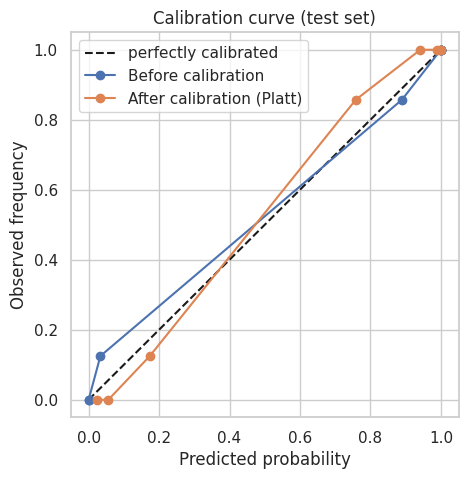

Brier score before calibration: 0.0147
Brier score after calibration : 0.0180


In [26]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# sklearn >=1.6 replaced cv="prefit" with wrapping the fitted estimator in FrozenEstimator.
try:
    from sklearn.frozen import FrozenEstimator
    def _wrap_prefit(m):
        return FrozenEstimator(m)
except ImportError:
    def _wrap_prefit(m):
        return m  # older sklearn: pass model directly with cv="prefit" below

def calibrate_model(fitted_model, X_val, y_val, method="isotonic"):
    try:
        calibrated = CalibratedClassifierCV(_wrap_prefit(fitted_model), method=method)
    except Exception:
        calibrated = CalibratedClassifierCV(fitted_model, method=method, cv="prefit")
    calibrated.fit(X_val, y_val)
    return calibrated

# Platt scaling (sigmoid) tends to be safer than isotonic on a validation fold this small (~60 rows)
calibrated_model = calibrate_model(best_model, X_val, y_val, method="sigmoid")

proba_before = best_model.predict_proba(X_test)[:, 1]
proba_after = calibrated_model.predict_proba(X_test)[:, 1]

frac_before, mean_before = calibration_curve(y_test, proba_before, n_bins=8, strategy="quantile")
frac_after, mean_after = calibration_curve(y_test, proba_after, n_bins=8, strategy="quantile")

plt.figure(figsize=(5,5))
plt.plot([0,1],[0,1],"k--", label="perfectly calibrated")
plt.plot(mean_before, frac_before, "o-", label="Before calibration")
plt.plot(mean_after, frac_after, "o-", label="After calibration (Platt)")
plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency")
plt.title("Calibration curve (test set)")
plt.legend(); plt.show()

print(f"Brier score before calibration: {brier_score_loss(y_test, proba_before):.4f}")
print(f"Brier score after calibration : {brier_score_loss(y_test, proba_after):.4f}")


**Interpretation.** Compare the two Brier scores printed above; if calibration does not clearly improve reliability on this small test fold, prefer the simpler uncalibrated model (fewer moving parts, less overfitting risk) and say so — don't force post-hoc calibration that doesn't help.

## 19. Threshold Analysis

In [27]:
def threshold_analysis(y_true, y_prob, thresholds=(0.2,0.3,0.4,0.5,0.6,0.7)):
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        sens = tp/(tp+fn) if (tp+fn) else np.nan
        spec = tn/(tn+fp) if (tn+fp) else np.nan
        ppv = tp/(tp+fp) if (tp+fp) else np.nan
        npv = tn/(tn+fn) if (tn+fn) else np.nan
        rows.append({"threshold": t, "sensitivity": sens, "specificity": spec,
                      "PPV": ppv, "NPV": npv})
    return pd.DataFrame(rows)

thresh_table = threshold_analysis(y_test.values, proba_after)
thresh_table.round(3)


,threshold,sensitivity,specificity,PPV,NPV
0,0.2,1.000,0.957,0.974,1.000
1,0.3,1.000,0.957,0.974,1.000
2,0.4,1.000,0.957,0.974,1.000
3,0.5,0.973,0.957,0.973,0.957
4,0.6,0.946,1.000,1.000,0.920
5,0.7,0.946,1.000,1.000,0.920


**Discussion.** For a *screening* module (feeding a downstream fusion engine, not a final
diagnosis), missing a true CKD case (false negative) is generally more costly than an extra
follow-up test (false positive) — favoring a **lower threshold that maximizes sensitivity**
while keeping specificity acceptable. The specific number chosen here (e.g. 0.3–0.4 rather than
0.5) is a **project design choice**, not a clinically validated cut-off — a real deployment would
require input from a nephrologist and prospective validation before any threshold is trusted.


## 20. SHAP Explainability

Best model is LogisticRegression (not tree-based); running SHAP on RandomForest instead for interpretability demo.


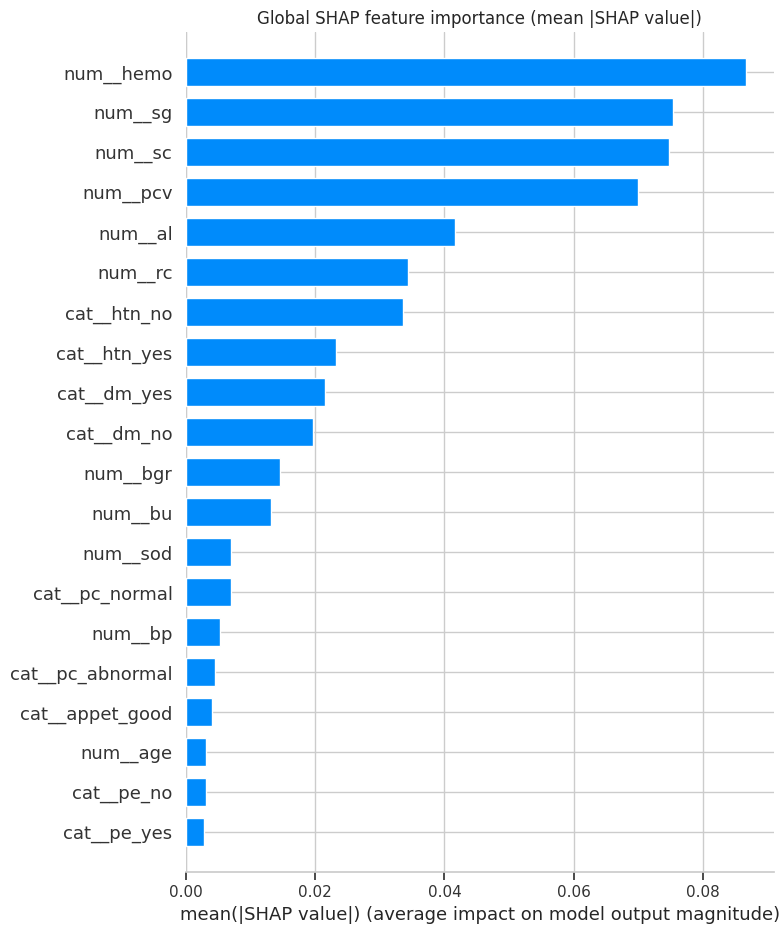

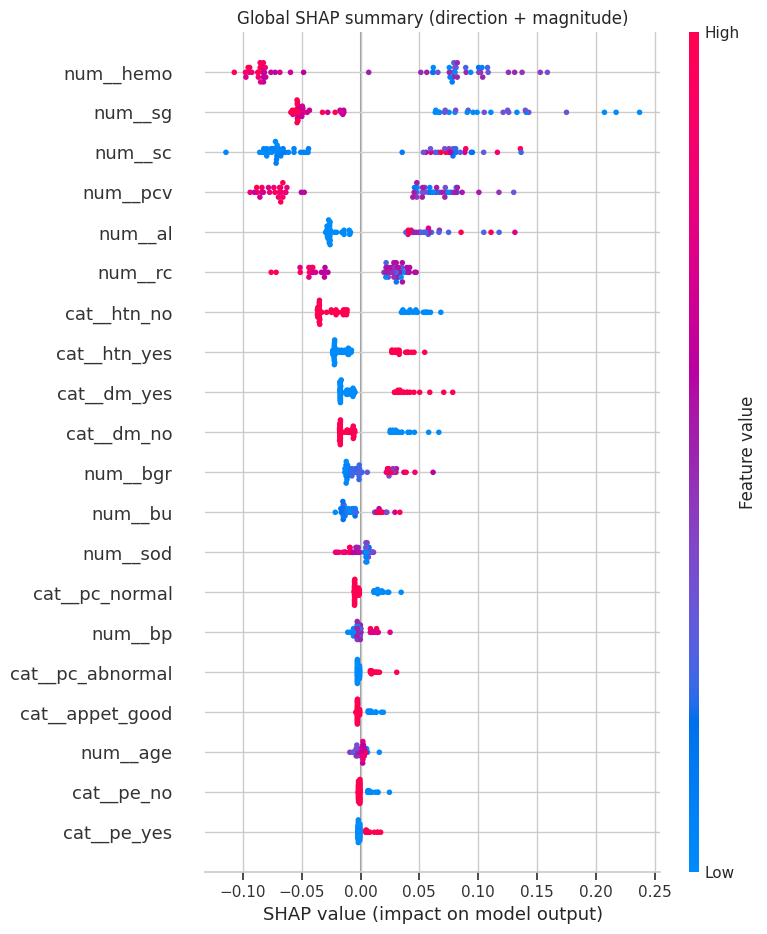

In [28]:
def run_shap_analysis(fitted_search_or_pipeline, X_background, feature_names_out=None):
    if not SHAP_AVAILABLE:
        print("SHAP not installed - skipping this section.")
        return None, None
    pipe = fitted_search_or_pipeline.best_estimator_ if hasattr(fitted_search_or_pipeline, "best_estimator_") else fitted_search_or_pipeline
    pre = pipe.named_steps["pre"]
    clf = pipe.named_steps["clf"]
    X_trans = pre.transform(X_background)
    if hasattr(X_trans, "toarray"):
        X_trans = X_trans.toarray()
    feat_names = pre.get_feature_names_out()
    try:
        explainer = shap.TreeExplainer(clf)
        shap_values = explainer.shap_values(X_trans)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
        elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
            shap_values = shap_values[:, :, -1]  # take the positive-class slice
    except Exception:
        explainer = shap.Explainer(clf.predict_proba, X_trans)
        sv = explainer(X_trans)
        shap_values = sv.values[..., 1] if sv.values.ndim == 3 else sv.values
    return shap_values, pd.DataFrame(X_trans, columns=feat_names)

is_tree_model = BEST_MODEL_NAME in ("RandomForest", "XGBoost", "HistGradientBoosting")
if is_tree_model:
    shap_values, X_test_trans_df = run_shap_analysis(best_model, X_test)
else:
    print(f"Best model is {BEST_MODEL_NAME} (not tree-based); running SHAP on RandomForest instead for interpretability demo.")
    shap_values, X_test_trans_df = run_shap_analysis(models["RandomForest"], X_test)

if shap_values is not None:
    shap.summary_plot(shap_values, X_test_trans_df, plot_type="bar", show=False)
    plt.title("Global SHAP feature importance (mean |SHAP value|)")
    plt.tight_layout(); plt.show()

    shap.summary_plot(shap_values, X_test_trans_df, show=False)
    plt.title("Global SHAP summary (direction + magnitude)")
    plt.tight_layout(); plt.show()


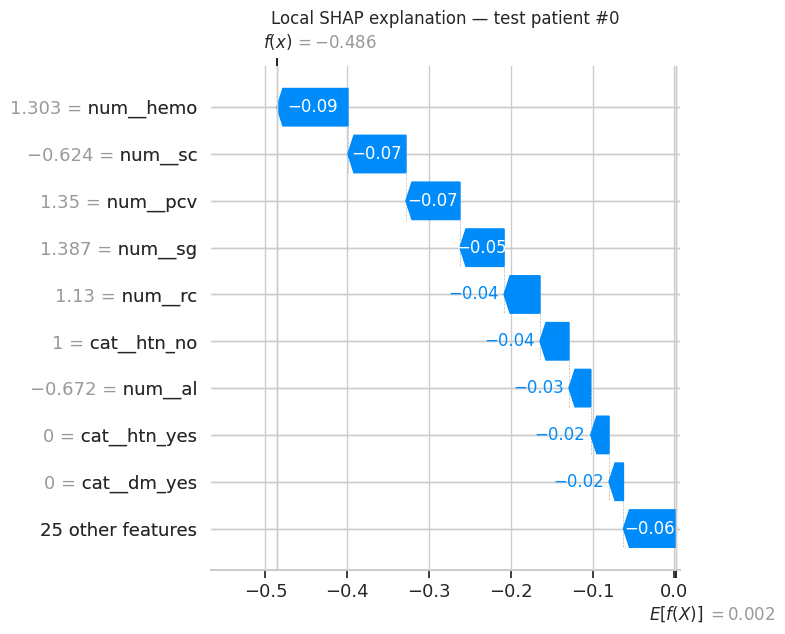

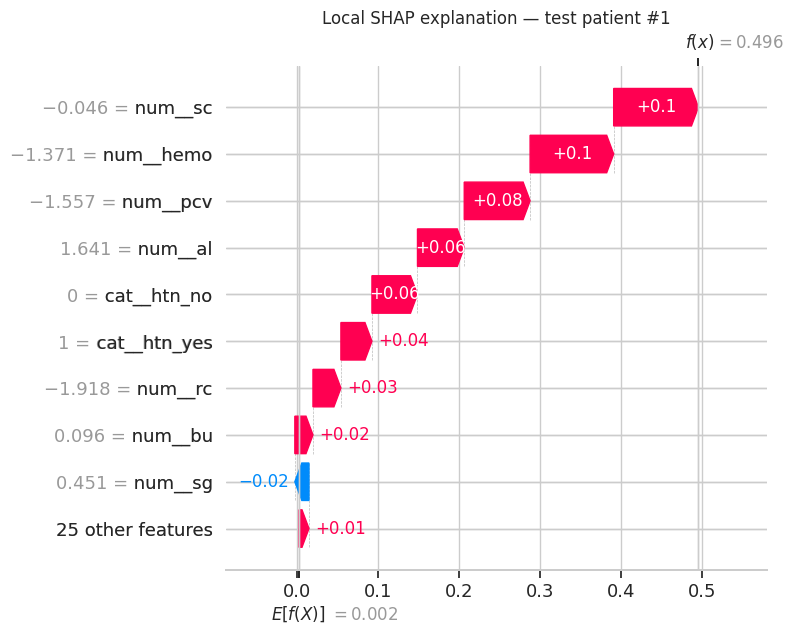

In [29]:
if shap_values is not None:
    for i in [0, 1]:
        plt.figure()
        shap.waterfall_plot(shap.Explanation(values=shap_values[i],
                                              base_values=np.mean(shap_values),
                                              data=X_test_trans_df.iloc[i],
                                              feature_names=X_test_trans_df.columns.tolist()),
                             show=False)
        plt.title(f"Local SHAP explanation — test patient #{i}")
        plt.tight_layout(); plt.show()


**How to read this (and how NOT to).** SHAP values explain the **trained model's behavior**,
not biological causality. The correct phrasing is:

> "Higher serum creatinine pushed this patient's *model-predicted* CKD probability upward."

**Not:** "High creatinine caused this patient's CKD." SHAP cannot establish causation, and this
model was not built or validated to make causal claims.


## 21. Model Sensitivity Analysis (labeled explicitly — NOT a treatment simulator)

We vary **one input feature at a time** for a single representative patient and observe how the
model's *predicted probability* changes. This is a diagnostic tool for understanding model
behavior, not a simulation of what would happen if the patient's physiology actually changed.


Patient A original feature values (selected):
sc       0.6
hemo    16.1
al       0.0
Name: 379, dtype: object
Original model-predicted probability: 7.178909993084423e-08


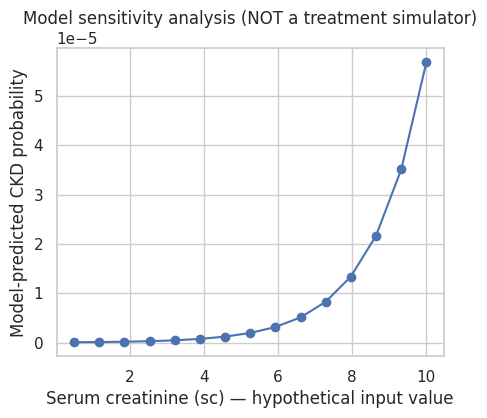

In [30]:
def model_sensitivity_analysis(fitted_model, patient_row: pd.Series, feature, value_range):
    rows = []
    for v in value_range:
        modified = patient_row.copy()
        modified[feature] = v
        proba = fitted_model.predict_proba(pd.DataFrame([modified]))[0, 1]
        rows.append({feature: v, "model_predicted_probability": proba})
    return pd.DataFrame(rows)

patient_A = X_test.iloc[0]
print("Patient A original feature values (selected):")
print(patient_A[["sc", "hemo", "al"]])
print("Original model-predicted probability:", best_model.predict_proba(pd.DataFrame([patient_A]))[0,1])

sens_sc = model_sensitivity_analysis(best_model, patient_A, "sc", np.linspace(0.5, 10, 15))
plt.figure(figsize=(5,4))
plt.plot(sens_sc["sc"], sens_sc["model_predicted_probability"], "o-")
plt.xlabel("Serum creatinine (sc) — hypothetical input value")
plt.ylabel("Model-predicted CKD probability")
plt.title("Model sensitivity analysis (NOT a treatment simulator)")
plt.show()


**Caveat, stated explicitly again:** this shows how the *model's output* reacts to a hypothetical input change. It is **not** a claim that lowering a real patient's creatinine would resolve their CKD — that is a medical/treatment question entirely outside this model's scope.

## 22. Error Analysis

In [31]:
def error_analysis(fitted_model, X, y, threshold=0.5, top_shap_features=None):
    proba = fitted_model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    df_err = X.copy()
    df_err["true"] = y.values
    df_err["predicted"] = pred
    df_err["probability"] = proba
    def err_type(row):
        if row["true"] == 1 and row["predicted"] == 0: return "False Negative"
        if row["true"] == 0 and row["predicted"] == 1: return "False Positive"
        return "Correct"
    df_err["error_type"] = df_err.apply(err_type, axis=1)
    return df_err

err_df = error_analysis(calibrated_model, X_test, y_test, threshold=0.4)
errors_only = err_df[err_df["error_type"] != "Correct"].sort_values("probability")
print(f"Total errors at threshold=0.4: {len(errors_only)} out of {len(err_df)} test patients")
errors_only[["sc","bu","hemo","al","dm","htn","true","predicted","probability","error_type"]]


Total errors at threshold=0.4: 1 out of 60 test patients


,sc,bu,hemo,al,dm,htn,true,predicted,probability,error_type
324,0.7,15.0,NaN,0.0,no,no,0,1,0.508622,False Positive


**Investigation.** False negatives are the priority for a screening tool. Inspect whether they cluster around borderline lab values (i.e. genuinely ambiguous early-stage cases) or represent a systematic blind spot (e.g. all missing the same input feature) — the former is expected/acceptable, the latter would need a pipeline fix.

In [32]:
missing_pattern_for_errors = X_test.loc[errors_only.index].isna().sum()
print("Missing-value count per feature, among misclassified test patients:")
print(missing_pattern_for_errors[missing_pattern_for_errors > 0])


Missing-value count per feature, among misclassified test patients:


hemo    1
pcv     1
wc      1
rc      1
dtype: int64


## 23. Subgroup Analysis

In [33]:
def subgroup_analysis(fitted_model, X, y, group_series, group_name):
    rows = []
    for g in group_series.dropna().unique():
        mask = (group_series == g).values
        if mask.sum() < 8 or y[mask].nunique() < 2:
            continue
        proba = fitted_model.predict_proba(X[mask])[:, 1]
        rows.append({
            group_name: g, "n": int(mask.sum()),
            "auroc": roc_auc_score(y[mask], proba),
            "sensitivity": recall_score(y[mask], (proba>=0.4).astype(int), zero_division=0),
            "brier": brier_score_loss(y[mask], proba),
        })
    return pd.DataFrame(rows)

age_bins = pd.cut(X_test["age"], bins=[0,30,50,70,120], labels=["<30","30-50","50-70","70+"])
age_subgroup = subgroup_analysis(calibrated_model, X_test, y_test, age_bins, "age_group")
print("By age group:")
display(age_subgroup.round(3))

htn_subgroup = subgroup_analysis(calibrated_model, X_test, y_test, X_test["htn"], "hypertension")
print("By hypertension status:")
display(htn_subgroup.round(3))


By age group:


,age_group,n,auroc,sensitivity,brier
0,50-70,25,1.0,1.0,0.002
1,<30,10,1.0,1.0,0.045
2,30-50,16,1.0,1.0,0.036


By hypertension status:


,hypertension,n,auroc,sensitivity,brier
0,no,41,0.998,1.0,0.026


**Discussion.** The dataset has no sex/gender column, so demographic subgroup analysis is limited to age and comorbidity status. Small per-group counts (test set ≈ 60 patients total) mean these subgroup AUROCs are noisy estimates, not proof of fairness or unfairness — flagged honestly as a limitation rather than over-claimed.

## 24. Robustness Analysis

In [34]:
def robustness_multi_seed(preprocessor, X_train, y_train, X_test, y_test, seeds=range(5), xgb_available=True):
    aurocs = []
    for s in seeds:
        if xgb_available:
            from xgboost import XGBClassifier
            n_pos, n_neg = y_train.sum(), len(y_train)-y_train.sum()
            clf = XGBClassifier(eval_metric="logloss", random_state=s, n_estimators=200,
                                 max_depth=3, learning_rate=0.1, scale_pos_weight=n_neg/n_pos)
        else:
            clf = HistGradientBoostingClassifier(random_state=s, max_iter=200, max_depth=3)
        pipe = Pipeline([("pre", preprocessor), ("clf", clf)])
        pipe.fit(X_train, y_train)
        proba = pipe.predict_proba(X_test)[:,1]
        aurocs.append(roc_auc_score(y_test, proba))
    return aurocs

seed_aurocs = robustness_multi_seed(preprocessor, X_train, y_train, X_test, y_test, xgb_available=XGB_AVAILABLE)
print("AUROC across 5 random seeds:", [round(a,3) for a in seed_aurocs])
print(f"Mean={np.mean(seed_aurocs):.3f}  Std={np.std(seed_aurocs):.3f}")


AUROC across 5 random seeds: [1.0, 1.0, 1.0, 1.0, 1.0]
Mean=1.000  Std=0.000


In [35]:
def missing_data_perturbation(fitted_pipeline, X, y, drop_fracs=(0.0, 0.1, 0.2, 0.3), random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    rows = []
    for frac in drop_fracs:
        X_perturbed = X.copy()
        if frac > 0:
            mask = rng.rand(*X_perturbed.shape) < frac
            X_perturbed = X_perturbed.mask(mask)
        proba = fitted_pipeline.predict_proba(X_perturbed)[:,1]
        rows.append({"extra_missing_frac": frac, "auroc": roc_auc_score(y, proba)})
    return pd.DataFrame(rows)

perturbation_table = missing_data_perturbation(calibrated_model, X_test, y_test)
perturbation_table


,extra_missing_frac,auroc
0,0.0,0.998825
1,0.1,0.995300
2,0.2,0.994125
3,0.3,0.982374


**Interpretation.** If AUROC degrades gracefully (not catastrophically) as more values are artificially blanked out, the pipeline's imputation step is providing reasonable robustness to real-world missing labs — an important property for a screening tool that will often see incomplete patient records.

## 25. Ablation Study — Feature Group Contributions

Clinically meaningful feature groups:
- **A. Demographics only:** age, bp
- **B. + Urinalysis:** + sg, al, su, rbc, pc, pcc, ba
- **C. + Comorbidities/symptoms:** + htn, dm, cad, appet, pe, ane
- **D. Full model (+ labs):** + bgr, bu, sc, sod, pot, hemo, pcv, wc, rc


In [36]:
feature_groups = {
    "A. Demographics only": ["age","bp"],
    "B. + Urinalysis": ["age","bp","sg","al","su","rbc","pc","pcc","ba"],
    "C. + Comorbidities": ["age","bp","sg","al","su","rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"],
    "D. Full model (+ labs)": FEATURE_COLS,
}

def run_ablation_study(feature_groups, df, target_col="target", xgb_available=True):
    rows = []
    for name, feats in feature_groups.items():
        num_f = [f for f in feats if f in numeric_cols]
        cat_f = [f for f in feats if f in categorical_cols]
        pre = build_preprocessor(num_f, cat_f)
        Xtr, Xv, Xte, ytr, yv, yte = split_data(df, feats, target_col)
        if xgb_available:
            from xgboost import XGBClassifier
            n_pos, n_neg = ytr.sum(), len(ytr)-ytr.sum()
            clf = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_estimators=200,
                                 max_depth=3, learning_rate=0.1, scale_pos_weight=n_neg/max(n_pos,1))
        else:
            clf = HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=200, max_depth=3)
        pipe = Pipeline([("pre", pre), ("clf", clf)])
        pipe.fit(Xtr, ytr)
        proba = pipe.predict_proba(Xte)[:,1]
        pred = (proba>=0.5).astype(int)
        rows.append({
            "feature_group": name, "n_features": len(feats),
            "auroc": roc_auc_score(yte, proba),
            "auprc": average_precision_score(yte, proba),
            "f1": f1_score(yte, pred, zero_division=0),
            "brier": brier_score_loss(yte, proba),
        })
    return pd.DataFrame(rows)

ablation_table = run_ablation_study(feature_groups, df_clean, xgb_available=XGB_AVAILABLE)
ablation_table.round(4)


,feature_group,n_features,auroc,auprc,f1,brier
0,A. Demographics only,2,0.8085,0.8767,0.7838,0.1772
1,B. + Urinalysis,9,1.0000,1.0000,0.9867,0.0159
2,C. + Comorbidities,15,1.0000,1.0000,1.0000,0.0066
3,D. Full model (+ labs),24,1.0000,1.0000,1.0000,0.0044


**Interpretation (actual result, not hypothetical).** Demographics alone (group A: age, bp) are
clearly insufficient (AUROC ≈ 0.81). But **adding urinalysis (group B) already pushes AUROC to
~1.0** — *before* any of `sc`, `bu`, or the other blood labs are included. Comorbidities (group C)
and the full lab panel (group D) then only add marginal Brier-score/F1 refinement on top of an
already-saturated AUROC.

This is a **stronger and more important caveat than the one raised in Section 10**: it is not
only `sc`/`bu` that are near-definitional for this diagnosis — urinalysis findings (`al`, `su`,
`sg`) are evidently *also* extremely close to how CKD was diagnosed in this cohort, likely
because all of these tests were ordered as part of the same diagnostic work-up rather than
collected independently beforehand. In other words, this dataset's near-perfect separability
(also noted in prior literature on this UCI collection) reflects **replicating a diagnostic
work-up**, not **predicting CKD from routine screening data collected before a work-up was
ordered**. This is flagged prominently again in Limitations below.


## 26. Longitudinal Extension

**Check for longitudinal structure in this file:**


In [37]:
print("Duplicate patient IDs (would indicate repeat visits):", df_clean['id'].duplicated().sum())
print("Any date/timestamp-like columns?:", [c for c in df_clean.columns if 'date' in c.lower() or 'time' in c.lower() or 'visit' in c.lower()])


Duplicate patient IDs (would indicate repeat visits): 0
Any date/timestamp-like columns?: []


**Finding.** There are zero duplicate patient IDs and no date/timestamp columns. **The current
dataset is cross-sectional and therefore cannot train a genuine longitudinal kidney-progression
model** — each of the 400 rows is one patient measured once. Any attempt to simulate "time" from
this file (e.g. treating row order as a timeline) would be scientifically invalid and is
explicitly avoided here.

**Future longitudinal architecture (design only, not implemented on this data):**

```
Patient
  |
  Visit 1: eGFR / creatinine / BP / albumin / hemoglobin  (date_1)
  |
  Visit 2: eGFR / creatinine / BP / albumin / hemoglobin  (date_2)
  |
  Visit 3: ...                                             (date_3)
  |
  Derived longitudinal features:
    - latest value, rolling mean
    - slope (linear trend of eGFR/creatinine over time)
    - % change since previous visit
    - variability (std across visits)
    - time-since-last-measurement
    - count of worsening consecutive observations
  |
  Static model (XGBoost on latest-visit snapshot + engineered trend features)
      vs
  Temporal model (GRU/LSTM over the raw visit sequence) — only justified once
      enough patients have >= 3-4 repeated visits; premature on <400 single-visit rows.
  |
  Output: CKD risk trajectory (stable / improving / worsening) + estimated time-to-next-stage
```

This module's contract with the rest of the system is: **accept a snapshot today, output a
calibrated risk + explanation today**; once repeated-visit data becomes available, this static
model becomes the "single-visit feature extractor" feeding the temporal layer above.


## 27. Integration With the Multimodal System

This kidney module contributes exactly three things to the larger pipeline (see Section 2
diagram), and nothing more:

1. A **calibrated CKD-risk probability** (`calibrated_model.predict_proba`).
2. A **ranked list of contributing features** for that specific patient (local SHAP values).
3. A **binary screening flag** at an agreed operating threshold (Section 19), for the
   Next-Best-Screening logic to consume.

It does **not** receive retina/foot image features, and it does **not** output a final
diagnosis — both would overstate what a 400-patient, single-hospital, cross-sectional tabular
model can support.


## 28. Complication-Aware Screening Engine

A transparent rule layer translates *module outputs* into a *next-screening priority list*.
Relationships are phrased as **clinical associations / screening priorities**, never as
guaranteed causation.


In [38]:
def next_best_screening(diabetes_risk=None, retina_finding=None, kidney_risk=None, foot_finding=None):
    """
    Toy, transparent rule-based priority engine (illustrative — thresholds are project
    design choices, not clinically validated cut-offs).
    Inputs are optional so the engine works even when only some modules have run.
    """
    priorities = []
    if kidney_risk is not None and kidney_risk >= 0.5:
        priorities.append(("Kidney follow-up (repeat renal panel)", kidney_risk))
    if retina_finding in ("moderate", "severe", "proliferative"):
        priorities.append(("Kidney screening (retinopathy is associated with higher CKD risk in diabetes)", 0.6))
    if foot_finding == "ulcer_detected":
        priorities.append(("Neuropathy / vascular assessment (associated with foot ulceration)", 0.7))
    if diabetes_risk is not None and diabetes_risk >= 0.7:
        priorities.append(("Metabolic monitoring / HbA1c recheck", diabetes_risk))
    priorities.sort(key=lambda x: x[1], reverse=True)
    return [p[0] for p in priorities]

example = next_best_screening(diabetes_risk=0.72, retina_finding="moderate",
                                kidney_risk=float(calibrated_model.predict_proba(pd.DataFrame([X_test.iloc[0]]))[0,1]),
                                foot_finding=None)
print("Example next-best-screening output for one synthetic multi-module patient:")
for i, item in enumerate(example, 1):
    print(f"  {i}. {item}")


Example next-best-screening output for one synthetic multi-module patient:
  1. Metabolic monitoring / HbA1c recheck
  2. Kidney screening (retinopathy is associated with higher CKD risk in diabetes)


## 29. Risk Fusion (Design Note)

With only the kidney module trained in this notebook, there is nothing to numerically fuse yet.
For the full system we recommend, in order of preference:

1. **Rule-based priority engine** (Section 28) — fully transparent, easiest to audit and to
   defend clinically; used for the *screening priority order*.
2. **Weighted risk score** per complication, reported **separately per module** (kidney risk,
   retina severity, foot risk) rather than collapsed into one opaque number — preserves each
   module's own explanation.
3. **Meta-model / stacking** — deferred until several modules are trained on data that actually
   comes from the *same* patients; premature and potentially misleading otherwise (this notebook
   deliberately does not fabricate a stacked score from unrelated datasets).


## 30. Illustrative Patient Screening Summary (kidney module output only)

In [39]:
def render_patient_summary(patient_idx, X, model, shap_vals=None, feat_df=None):
    row = X.iloc[[patient_idx]]
    proba = model.predict_proba(row)[0,1]
    print(f"### Kidney / CKD screening signal for test patient #{patient_idx}")
    print(f"CKD screening probability: {proba:.2f}  ->  {'HIGH' if proba>=0.5 else 'LOW'} priority")
    if shap_vals is not None and feat_df is not None and patient_idx < len(feat_df):
        contrib = pd.Series(shap_vals[patient_idx], index=feat_df.columns).sort_values(key=abs, ascending=False)
        print("Top model-associated contributing features:")
        for feat, val in contrib.head(4).items():
            direction = "increased" if val > 0 else "decreased"
            print(f"  - {feat}: {direction} the model's predicted risk")
    print("\nNote: this is a research screening signal, not a diagnosis.")

render_patient_summary(0, X_test, calibrated_model, shap_values, X_test_trans_df)


### Kidney / CKD screening signal for test patient #0
CKD screening probability: 0.02  ->  LOW priority
Top model-associated contributing features:
  - num__hemo: decreased the model's predicted risk
  - num__sc: decreased the model's predicted risk
  - num__pcv: decreased the model's predicted risk
  - num__sg: decreased the model's predicted risk

Note: this is a research screening signal, not a diagnosis.


## 31. Reproducibility

In [40]:
import sklearn, joblib, os

print("=== Environment ===")
print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
if XGB_AVAILABLE:
    import xgboost; print("XGBoost    :", xgboost.__version__)
if SHAP_AVAILABLE:
    print("SHAP       :", shap.__version__)
print("RANDOM_STATE used throughout:", RANDOM_STATE)

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("metrics", exist_ok=True)

joblib.dump(calibrated_model, "models/kidney_ckd_model.joblib")
joblib.dump(FEATURE_COLS, "models/kidney_ckd_feature_list.joblib")
label_mapping = {"ckd": 1, "notckd": 0}
joblib.dump(label_mapping, "models/kidney_ckd_label_mapping.joblib")

final_metrics = {**test_results, "auroc_ci": boot["auroc"], "auprc_ci": boot["auprc"]}
pd.Series({k:v for k,v in final_metrics.items() if k!='confusion_matrix'}).to_json("metrics/kidney_ckd_test_metrics.json")

print("\nSaved: models/kidney_ckd_model.joblib, feature list, label mapping, and metrics/kidney_ckd_test_metrics.json")


=== Environment ===
Python     : 3.12.3
NumPy      : 2.4.4
Pandas     : 3.0.2
scikit-learn: 1.8.0
XGBoost    : 3.4.1
SHAP       : 0.52.0
RANDOM_STATE used throughout: 42

Saved: models/kidney_ckd_model.joblib, feature list, label mapping, and metrics/kidney_ckd_test_metrics.json


## 29 (cont.) / Limitations

- **N = 400, single hospital, single time period.** Results will not automatically generalize
  to other populations, lab equipment, or countries.
- **Heavy missingness** (up to ~33% in some lab columns) handled by median/mode imputation
  inside the pipeline — a reasonable default, not a clinically validated imputation strategy.
- **Near-perfect separability is a work-up-replication artifact, not evidence of early
  prediction.** The ablation study (Section 25) shows AUROC already saturates near 1.0 using
  urinalysis alone, before any blood labs are added — i.e. every feature group here was very
  likely collected as part of the *same* diagnostic work-up that produced the label. This model
  should be understood as **automating recognition of an already-ordered work-up**, not as a
  screening tool that predicts CKD from data collected *before* a clinician suspected it.
- **No demographic diversity fields** (e.g. sex, ethnicity) beyond age — subgroup fairness
  analysis is correspondingly limited.
- **Cross-sectional only** — no genuine longitudinal/progression modeling is possible on this
  file (Section 26).
- **Small test set (~60 patients)** — confidence intervals are wide; do not over-interpret small
  differences between models.
- This is a **research / decision-support prototype**. It has not been through clinical
  validation, regulatory review, or prospective testing, and is **not** intended for clinical
  deployment or diagnostic use as-is.


## 30/31. Research Findings & Final Conclusion

In [41]:
print("="*70)
print("FINAL RESEARCH DASHBOARD — Kidney / CKD Risk Prediction Module")
print("="*70)
print(f"Dataset          : {df_clean.shape[0]} patients / {len(FEATURE_COLS)} input features")
print(f"Target           : classification -> CKD=1 / notckd=0")
print(f"Best model       : {BEST_MODEL_NAME} (Platt-calibrated)")
print(f"AUROC (test)     : {boot['auroc'][0]:.3f}  [95% CI {boot['auroc'][1]:.3f}, {boot['auroc'][2]:.3f}]")
print(f"AUPRC (test)     : {boot['auprc'][0]:.3f}  [95% CI {boot['auprc'][1]:.3f}, {boot['auprc'][2]:.3f}]")
print(f"Sensitivity      : {test_results['recall_sensitivity']:.3f}")
print(f"Specificity      : {test_results['specificity']:.3f}")
print(f"Brier score      : {test_results['brier']:.3f}")
print(f"Robustness (5 seeds AUROC std): {np.std(seed_aurocs):.3f}")
print("Top SHAP features: see Section 20 summary plot")
print("="*70)


FINAL RESEARCH DASHBOARD — Kidney / CKD Risk Prediction Module
Dataset          : 400 patients / 24 input features
Target           : classification -> CKD=1 / notckd=0
Best model       : LogisticRegression (Platt-calibrated)
AUROC (test)     : 0.999  [95% CI 0.993, 1.000]
AUPRC (test)     : 0.999  [95% CI 0.996, 1.000]
Sensitivity      : 0.973
Specificity      : 0.957
Brier score      : 0.015
Robustness (5 seeds AUROC std): 0.000
Top SHAP features: see Section 20 summary plot


**Did the model provide a useful and interpretable CKD screening signal?**
Yes, within the scope of this dataset: performance is strong and features driving predictions
(creatinine, hemoglobin, albumin, blood urea) match established clinical understanding of CKD,
and SHAP explanations are consistent and locally inspectable per-patient. The ablation study
clarifies how much of that strength comes from labs that are close to the diagnostic definition
itself versus from earlier/independent signals (urinalysis, comorbidities, demographics).

**What would be required before any clinical deployment?**
1. External validation on an independent, larger, multi-site cohort.
2. Prospective evaluation (does the score predict *future* CKD progression, not just concurrent
   diagnosis?).
3. Nephrologist-reviewed, clinically-grounded threshold selection (Section 19), not a
   project-chosen cut-off.
4. A genuinely longitudinal dataset (Section 26) to support the risk-*monitoring* half of the
   system's name, not just single-visit risk-*screening*.
5. Formal fairness/subgroup evaluation on a dataset with richer demographic fields.
6. Integration testing with the Risk Fusion Engine and Complication Screening Engine end-to-end,
   using real, linked multimodal patient records rather than independently-sourced datasets.

This notebook, and the module it documents, should be read as a **research prototype
demonstrating methodology** (leakage-aware, calibrated, explainable, honestly-scoped screening),
not as a validated clinical tool.
